# **INFO 2950 Final Project Phase II**
Aiden Hwang, Anthony Ruiz, Youssef Sarhan

### **Research Question**
How has AI and Machine Learning (AI / ML) content spread across course levels (1000-2000 introductory, 3000-4000 upper-level, and 5000+ graduate) and academic disciplines in Cornell's course offerings from Fall 2014 to Spring 2025, and does that spread track public interest in AI as measured by Google Trends?

What we mean by "AI/ML content": a course offering counts as AI/ML if its  title or catalog description contains at least one of our AI/ML keywords (listed in the variable section below).

### **Data Collection**

We collected two datasets outside this notebook and saved them as CSV files in our GitHub repository (https://github.com/Aidennnnnnnnnn/2950-final-project).

**1. Cornell course listings (`cornell_courses_raw.csv`)**
* **Source:** the public Cornell Class Roster API (https://classes.cornell.edu/api/2.0/), collected with our script `scrape_cornell.py`.
* **Semesters:** all 22 Fall and Spring semesters from Fall 2014 (FA14) through Spring 2025 (SP25). We omitted Summer and Winter sessions because they are short, offer few courses, and are not a good representation of Cornell's academic intent.
* **Subjects:** 18 subject codes that cover major subject areas: computing (CS, INFO), engineering and math/statistics (ECE, ORIE, STSCI, MATH), natural sciences (PHYS, BIOG), social sciences and business (ECON, GOVT, PSYCH, SOC, COMM, AEM, HD), and humanities (PHIL, ENGL, HIST). Scraping every subject (100+) at the API's limit of one request per second was not practical nor necessary for Phase II, so we took this sampling approach.
* **How the script works:** it first asks the API which semesters and subject codes exist, and then it requests one page per combination with at least 1.05 seconds between requests, as the politeness rule asks. Every response is cached and every request is logged in `fetch_log.csv`.
* **What the script keeps:** semester, subject, catalog number, Cornell's internal course ID (`crse_id`), title, and description.
* **What is not included yet:** starting in Fall 2025, Cornell moved its listings to a new catalog system with a different format. We have not collected Fall 2025–Fall 2026 yet.

**2. Google Trends (`google_trends_raw.csv`)**
* We used the pytrends Python library to download monthly U.S. search interest for "machine learning", "artificial intelligence", and "neural network" from January 2014 to October 2026, all in one request so the three terms share the same 0–100 scale.

In [1]:
# Load both files
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_colwidth", 70)

courses_raw = pd.read_csv("cornell_courses_raw.csv")
trends_raw = pd.read_csv("google_trends_raw.csv")

print(f"Raw course listings: {courses_raw.shape[0]:,} rows x {courses_raw.shape[1]} columns")
print(f"Raw Google Trends:   {trends_raw.shape[0]} months x {trends_raw.shape[1]} columns\n")
print(f"Semesters: {courses_raw['roster'].nunique()} ({courses_raw['roster'].iloc[0]} to {courses_raw['roster'].iloc[-1]})")
print(f"Subjects:  {courses_raw['subject'].nunique()} -> {sorted(courses_raw['subject'].unique())}\n")
print("Missing values per column:")
print(courses_raw.isna().sum())

courses_raw.head(3)

Raw course listings: 21,305 rows x 10 columns
Raw Google Trends:   154 months x 5 columns

Semesters: 22 (FA14 to SP25)
Subjects:  18 -> ['AEM', 'BIOG', 'COMM', 'CS', 'ECE', 'ECON', 'ENGL', 'GOVT', 'HD', 'HIST', 'INFO', 'MATH', 'ORIE', 'PHIL', 'PHYS', 'PSYCH', 'SOC', 'STSCI']

Missing values per column:
roster               0
year                 0
semester             0
queried_subject      0
subject              0
catalog_nbr          0
crse_id              0
title                0
description        551
catalog_dttm         0
dtype: int64


,roster,year,semester,queried_subject,subject,catalog_nbr,crse_id,title,description,catalog_dttm
0,FA14,2014,Fall,CS,CS,1110,358526,Introduction to Computing Using Python,Programming and problem solving using Python. Emphasizes principle...,2015-06-11T18:21:23-0400
1,FA14,2014,Fall,CS,CS,1112,358525,Introduction to Computing Using MATLAB,Programming and problem solving using MATLAB. Emphasizes the syste...,2015-06-11T18:21:23-0400
2,FA14,2014,Fall,CS,CS,1132,361641,Transition to MATLAB,Introduction to MATLAB and scientific computing. Covers the MATLAB...,2015-06-11T18:21:23-0400


### **Data Cleaning**

#### Step 1: Deciding which columns to keep

Our question needs when the course was offered, which department it was offered in, and whether it covers AI / ML. Other columns / rows that don't help with our goals are dropped.

| Raw column | Keep? | Why |
|---|---|---|
| `roster` | Keep | The semester code (e.g., `FA14`). Together with `crse_id`, it identifies a single class in a single semester, which we need to find cross-listed courses. |
| `year`, `semester` | Keep | Time is the backbone of our question. They are also how we join the Google Trends data. |
| `subject` | Keep | The department code (e.g., `CS`, `ECON`). We group these into broad disciplines for our second analysis. |
| `catalog_nbr` | Keep | The course number (e.g., `4780`). Its first digit tells us the course level, which our first analysis is about. |
| `crse_id` | Keep | Cornell's internal ID for a course. A cross-listed course (e.g., CS 4780 = ORIE 4780) has one `crse_id` but several listings, so this is how we avoid counting one class twice. |
| `title`, `description` | Keep | The text we search for AI/ML keywords. |
| `queried_subject` | **Drop** | The subject code our script asked for. We check below that it always equals `subject`. If so, it is a duplicate column. |
| `catalog_dttm` | **Drop** | The date Cornell last published that semester's catalog. It describes the catalog file, not the course, so it can't tell us anything about AI/ML adoption. |

The API offers many other fields we chose not to collect, such as meeting times, rooms, enrollment caps, and grading basis.

In [2]:
# queried_subject is redundant only if it never differs from subject
print("Rows where subject != queried_subject:",
      (courses_raw["subject"] != courses_raw["queried_subject"]).sum())

# catalog_dttm only has one value per published catalog but not per course
print("Distinct catalog_dttm values:", courses_raw["catalog_dttm"].nunique(),
      "for", courses_raw["roster"].nunique(), "semesters")

df = courses_raw.drop(columns=["queried_subject", "catalog_dttm"]).copy()
print("\nColumns kept:", df.columns.tolist())

Rows where subject != queried_subject: 0
Distinct catalog_dttm values: 20 for 22 semesters

Columns kept: ['roster', 'year', 'semester', 'subject', 'catalog_nbr', 'crse_id', 'title', 'description']


#### Step 2: Missing values, text formatting, and duplicate rows

* **Missing identifiers.** A row without a semester, subject, course number, ID, or title can't be placed anywhere in our analysis, so we drop it. The check above shows there are none, but we keep the step so the notebook stays correct if the data is re-scraped, which we might have to do for the newer data for 2026.
* **Missing descriptions.** A few of the listings have a missing or blank description. We kept them because their titles can still mention AI/ML (e.g., "Machine Learning"). We fill the gap with an empty string so text searches don't crash, and we record a `has_description` flag so we know these courses could only be classified from their title.
* **Extra spaces.** We strip leading and trailing spaces from text so the same subject or title always looks identical.
* **Duplicate listings.** The same subject, course number, and semester appearing twice would be a scraping error, so we check for and remove those.

In [3]:
n_start = len(df)

# Drop rows that are missing an identifier we need
df = df.dropna(subset=["roster", "year", "semester", "subject", "catalog_nbr", "crse_id", "title"])
print(f"Dropped {n_start - len(df)} rows missing an identifier")

# Keep courses without descriptions, but flag them
df["has_description"] = df["description"].notna() & (df["description"].str.strip() != "")
df["description"] = df["description"].fillna("")
print(f"{(~df['has_description']).sum()} listings ({(~df['has_description']).mean():.1%}) "
      "have no description and can only be classified from their title")

# Standardize text
for col in ["subject", "title", "description"]:
    df[col] = df[col].str.strip()

# Remove accidental duplicate listings
n_dups = df.duplicated(subset=["roster", "subject", "catalog_nbr"]).sum()
df = df.drop_duplicates(subset=["roster", "subject", "catalog_nbr"])
print(f"Removed {n_dups} duplicate subject-number-semester rows")
print(f"Listings after Step 2: {len(df):,}")

Dropped 0 rows missing an identifier
560 listings (2.6%) have no description and can only be classified from their title
Removed 0 duplicate subject-number-semester rows
Listings after Step 2: 21,305


#### Step 3: Create the variables our analyses need

**`course_level`** (Intro / Upper / Grad), from the first digit of `catalog_nbr`:
* `Intro` = 1000–2999: introductory and foundational undergraduate courses.
* `Upper` = 3000–4999: advanced undergraduate courses.
* `Grad` = 5000 and above: graduate and professional courses.

Courses numbered below 1000 (non-credit or PE) would be dropped, since they aren't part of a degree curriculum. None exist in our 18 subjects. We also create `is_intro` and `is_upper` (1 or 0) for the regression, with `Grad` as the comparison group.

**`is_ai`** (1 or 0): we lowercase `title + description` and search for whole-word matches (`\b` word boundaries) of these keywords:

`machine learning`, `artificial intelligence`, `neural network(s)`, `deep learning`, `computer vision`, `natural language processing`, `reinforcement learning`, `large language model(s)`, `generative ai`

* **Why these terms:** each one names an AI/ML method or field specifically.
* **Why not shorter terms:** we left out "AI" by itself, "learning", "neural", "data", and "algorithm". Word boundaries alone can't stop those from matching unrelated courses (e.g., "neural" in neuroscience, "learning" in education).
* **`ai_keyword`:** we also save which keyword matched, so we can check our flags by hand later.

**`discipline`**: 18 subject codes are too many to compare, so we group them into the five broad areas we sampled. This is the "academic discipline" in our research question.

| Discipline | Subjects |
|---|---|
| Computing | CS, INFO |
| Engineering & Math/Stats | ECE, ORIE, STSCI, MATH |
| Natural Sciences | PHYS, BIOG |
| Social Sciences & Business | ECON, GOVT, PSYCH, SOC, COMM, AEM, HD |
| Humanities | PHIL, ENGL, HIST |

**`is_computing`** (1 = CS or INFO): these two make up Cornell Bowers CIS, the computing college, so they are where we expect AI/ML to start. Engineering and statistics departments also teach a lot of ML. A second version, **`is_computing_broad`**, also counts Engineering & Math/Stats as computing, so we can check whether our conclusions depend on that choice.

**Time variables:**
* **`term_index`:** counts semesters from Fall 2014 (0, 1, 2, …).
* **`years_since_start`:** `term_index / 2`, so regression slopes are "change per year," and 0 means Fall 2014 (the start of our window).
* **`academic_year`:** pairs each Fall with the following Spring (e.g., "2014–15"). We use it for plots because every academic year then has two semesters. Calendar year 2025 would only contain one.

In [4]:
# --- course_level from the catalog number ---
def assign_course_level(num):
    if 1000 <= num < 3000:
        return "Intro"
    if 3000 <= num < 5000:
        return "Upper"
    if num >= 5000:
        return "Grad"
    return np.nan   # below 1000: non-credit courses

df["catalog_nbr"] = df["catalog_nbr"].astype(int)
df["course_level"] = df["catalog_nbr"].apply(assign_course_level)
print("Listings without a degree-course level (dropped):", df["course_level"].isna().sum())
df = df.dropna(subset=["course_level"])
df["is_intro"] = (df["course_level"] == "Intro").astype(int)
df["is_upper"] = (df["course_level"] == "Upper").astype(int)

# --- is_ai: whole-word keyword search on title + description ---
AI_KEYWORDS = [
    "machine learning", "artificial intelligence", "neural networks?", "deep learning",
    "computer vision", "natural language processing", "reinforcement learning",
    "large language models?", "generative ai",
]
keyword_regex = r"\b(" + "|".join(AI_KEYWORDS) + r")\b"
text = (df["title"] + " " + df["description"]).str.lower()
df["ai_keyword"] = text.str.extract(keyword_regex, expand=False).str.replace(r"s$", "", regex=True)
df["is_ai"] = df["ai_keyword"].notna().astype(int)

# --- discipline groups and computing indicators ---
DISCIPLINE = {
    "CS": "Computing", "INFO": "Computing",
    "ECE": "Engineering & Math/Stats", "ORIE": "Engineering & Math/Stats",
    "STSCI": "Engineering & Math/Stats", "MATH": "Engineering & Math/Stats",
    "PHYS": "Natural Sciences", "BIOG": "Natural Sciences",
    "ECON": "Social Sciences & Business", "GOVT": "Social Sciences & Business",
    "PSYCH": "Social Sciences & Business", "SOC": "Social Sciences & Business",
    "COMM": "Social Sciences & Business", "AEM": "Social Sciences & Business",
    "HD": "Social Sciences & Business",
    "PHIL": "Humanities", "ENGL": "Humanities", "HIST": "Humanities",
}
df["discipline"] = df["subject"].map(DISCIPLINE)
assert df["discipline"].notna().all(), "Every subject must belong to a discipline group"
df["is_computing"] = df["subject"].isin(["CS", "INFO"]).astype(int)
df["is_computing_broad"] = df["discipline"].isin(["Computing", "Engineering & Math/Stats"]).astype(int)

# --- time variables ---
df["term_index"] = (df["year"] - 2014) * 2 - (df["semester"] == "Spring").astype(int)
df["years_since_start"] = df["term_index"] / 2
ay_start = np.where(df["semester"] == "Fall", df["year"], df["year"] - 1)
df["academic_year"] = [f"{y}–{str(y + 1)[-2:]}" for y in ay_start]

print(f"AI/ML-flagged listings: {df['is_ai'].sum()} of {len(df):,} ({df['is_ai'].mean():.2%})")
df[["roster", "subject", "catalog_nbr", "title", "course_level", "discipline",
    "is_ai", "ai_keyword", "term_index", "academic_year"]].sample(5, random_state=2950)

Listings without a degree-course level (dropped): 0
AI/ML-flagged listings: 834 of 21,305 (3.91%)


,roster,subject,catalog_nbr,title,course_level,discipline,is_ai,ai_keyword,term_index,academic_year
8669,SP19,PSYCH,3820,Prejudice and Stereotyping,Upper,Social Sciences & Business,0,NaN,9,2018–19
758,FA14,HIST,3710,World War II in Europe,Upper,Humanities,0,NaN,0,2014–15
12554,SP21,COMM,3080,Capstone Course in Environmental and Sustainability Communication:...,Upper,Social Sciences & Business,0,NaN,13,2020–21
18492,SP24,MATH,4540,Introduction to Differential Geometry,Upper,Engineering & Math/Stats,0,NaN,19,2023–24
45,FA14,CS,5454,Mobile and Ubiquitous Computing,Grad,Computing,0,NaN,0,2014–15


#### Step 4: Remove placeholder courses (independent study, thesis, internships)

Some catalog entries aren't real courses with a topic. They are placeholders for things like "Independent Study," "Thesis Research," or "MEng Internship." They are listed every semester, usually have generic descriptions, and are mostly at the graduate level.

If we kept them, they would add hundreds of "non-AI" courses to the denominator, mostly in `Grad`. That would make graduate AI/ML shares look smaller, for a reason that has nothing to do with curriculum.

We identify them with a narrow title pattern and confirm that **none of them matched an AI/ML keyword**. So removing them can't hide any AI/ML courses; it only removes noise from the total.

In [5]:
placeholder_regex = (
    r"(?i)\b(?:independent (?:study|research)|thesis|dissertation|"
    r"supervised research|undergraduate research|internship)\b|^graduate research$"
)
df["is_placeholder"] = df["title"].str.contains(placeholder_regex, regex=True)

print(f"Placeholder listings: {df['is_placeholder'].sum():,} ({df['is_placeholder'].mean():.1%} of all listings)")
print("AI/ML-flagged placeholders:", int(df.loc[df["is_placeholder"], "is_ai"].sum()))
print("\nPlaceholders by level:")
print(df.loc[df["is_placeholder"], "course_level"].value_counts().to_string())

removed = df[df["is_placeholder"]]
df = df[~df["is_placeholder"]].drop(columns="is_placeholder")
print(f"\nListings after Step 4: {len(df):,}")
removed["title"].value_counts().head(8).to_frame("listings removed")

Placeholder listings: 1,076 (5.1% of all listings)
AI/ML-flagged placeholders: 0

Placeholders by level:
course_level
Grad     616
Upper    460

Listings after Step 4: 20,229


,listings removed
title,
Independent Study,118
Thesis Research,94
Independent Research,66
Independent Study in Physics,44
Graduate Research,44
Doctoral Level Dissertation Research,22
Master of Engineering Internship,22
Graduate Level Dissertation Research,22


#### Step 5: Handle cross-listed courses

Many Cornell classes are **cross-listed**, meaning the same class appears under several departments. For example, Machine Learning is listed as both CS 4780 and ORIE 4780. In the data, all listings of one class share the same `roster` and `crse_id`.

Whether to count a cross-listed class once or once per department depends on what each analysis asks, so we build **two tables**:

* **`courses_unique`** keeps one row per class per semester. **Used in Analysis 1 (course level).** Here we care how many *classes* at each level cover AI/ML. Counting CS 4780 and ORIE 4780 separately would make one class look like two. When a class has several listings, we keep the first in our subject order (CS, INFO, ECE, ORIE, …), which is the same rule as `cornell_courses_dedup.csv` from our scraper.
* **`courses`** keeps one row per department listing. **Used in Analysis 2 (departments).** Here the question is which departments offer AI/ML to their students. A department that cross-lists an AI class has decided to put it in its own catalog, so it gets credit. We flag every cross-listed row with `is_crosslisted` so we can test later whether non-computing growth comes from cross-listing rather than new courses.

In [6]:
listings_per_class = df.groupby(["roster", "crse_id"])["subject"].transform("nunique")
df["is_crosslisted"] = (listings_per_class > 1).astype(int)

courses = df.copy()                                                              # Analysis 2
courses_unique = df.drop_duplicates(subset=["roster", "crse_id"], keep="first").copy()  # Analysis 1

print(f"Listings that are part of a cross-listed class: {df['is_crosslisted'].sum():,} ({df['is_crosslisted'].mean():.1%})")
print(f"courses        (one row per department listing): {len(courses):,} rows, {courses['is_ai'].sum()} AI/ML")
print(f"courses_unique (one row per class per semester): {len(courses_unique):,} rows, {courses_unique['is_ai'].sum()} AI/ML")

mixed = df.groupby(["roster", "crse_id"])["course_level"].nunique()
print(f"Cross-listed classes whose listings fall in different levels: {(mixed > 1).sum()} "
      f"of {(df.groupby(['roster', 'crse_id']).size() > 1).sum():,}")

pairs = (df[df["is_crosslisted"] == 1].groupby(["roster", "crse_id"])["subject"]
         .apply(lambda s: " / ".join(sorted(s))))
pairs.value_counts().head(8).to_frame("class-semesters")

Listings that are part of a cross-listed class: 2,759 (13.6%)
courses        (one row per department listing): 20,229 rows, 834 AI/ML
courses_unique (one row per class per semester): 18,774 rows, 747 AI/ML
Cross-listed classes whose listings fall in different levels: 42 of 1,304


,class-semesters
subject,
HD / PSYCH,169
COMM / INFO,143
CS / INFO,139
AEM / ECON,113
GOVT / HIST,76
ORIE / STSCI,58
CS / MATH,56
CS / ECE,50


#### Step 6: Audit the AI/ML flag

A keyword search is only useful if the courses it flags are actually about AI/ML. Below we count which keyword triggered each flag, then list flagged courses **outside** Computing and Engineering. That is where a match is most likely to be a false positive (e.g., "neural network" meaning brain circuits). This list feeds directly into our Data Limitations section, and into the hand-labeled validation we plan for Phase III.

In [7]:
print("Which keyword triggered each AI/ML flag (unique classes):")
print(courses_unique.loc[courses_unique["is_ai"] == 1, "ai_keyword"].value_counts().to_string())

outside = courses[(courses["is_ai"] == 1) &
                  (~courses["discipline"].isin(["Computing", "Engineering & Math/Stats"]))]
print(f"\nAI/ML-flagged listings outside Computing and Engineering & Math/Stats: {len(outside)}")
(outside.groupby(["subject", "catalog_nbr", "title", "ai_keyword"])
        .size().rename("semesters offered").reset_index()
        .sort_values("semesters offered", ascending=False).head(15))

Which keyword triggered each AI/ML flag (unique classes):
ai_keyword
machine learning               343
artificial intelligence        162
computer vision                 85
natural language processing     64
reinforcement learning          39
neural network                  31
deep learning                   20
large language model             3

AI/ML-flagged listings outside Computing and Engineering & Math/Stats: 69


,subject,catalog_nbr,title,ai_keyword,semesters offered
3,ECON,2040,Networks,neural network,11
23,SOC,2090,Networks,neural network,11
11,HD,2940,Data Science for Social Scientists II,machine learning,4
6,ECON,6591,Empirical Strategies for Policy Research II,machine learning,4
21,PSYCH,3300,Introduction to Computational Neuroscience,neural network,4
8,ECON,7245,Topics in Econometrics and Machine Learning,machine learning,3
7,ECON,7240,Causal Inference and Machine Learning,machine learning,3
20,PSYCH,3020,Methods in Neuroscience,machine learning,3
9,GOVT,3042,The Politics of Technology,artificial intelligence,3
22,PSYCH,6020,Methods in Neuroscience,machine learning,3


#### Step 7: Clean Google Trends and connect it to semesters

Google Trends gives one score per month, while our course data is per semester. Our steps:

1. **Drop incomplete months.** October 2026 is marked `isPartial = True` (the month wasn't over when we downloaded it), so its score isn't comparable.
2. **Keep only months our course data can use.** That is January 2014 through May 2025. January–May 2014 is kept because Fall 2014 courses need the *previous* semester's score (step 5).
3. **Map months to semesters.** Spring = January–May, Fall = August–December. June and July fall between semesters and are dropped.
4. **Combine and rescale.** We average the three search terms into one composite score per month, then average months within each semester. Google scales every pull so the single highest month is 100. Our pull's peak (mid-2026) is far outside our window, which squeezes 2014–2025 into roughly 2–20. We rescale so the highest semester *inside* our window equals 100 (`trends_index`). This is a straight multiplication, so it changes no comparisons between semesters; it only makes the numbers readable.
5. **Lag by one semester.** Departments schedule courses about a semester ahead, so a Fall course can only respond to interest during the previous Spring. `trends_lag1` is the previous semester's `trends_index`.

In [8]:
trends = trends_raw.copy()
trends["date"] = pd.to_datetime(trends["date"])

print("Incomplete months dropped:", int(trends["isPartial"].sum()))
trends = trends[~trends["isPartial"]]
trends = trends[(trends["date"] >= "2014-01-01") & (trends["date"] <= "2025-05-31")].copy()

SEARCH_TERMS = ["machine learning", "artificial intelligence", "neural network"]
trends["composite"] = trends[SEARCH_TERMS].mean(axis=1)
trends["year"] = trends["date"].dt.year
month = trends["date"].dt.month
trends["semester"] = np.select([month <= 5, month >= 8], ["Spring", "Fall"], default="Summer")
trends = trends[trends["semester"] != "Summer"]

sem_trends = trends.groupby(["year", "semester"], as_index=False)["composite"].mean()
sem_trends["order"] = sem_trends["year"] * 2 + (sem_trends["semester"] == "Fall")
sem_trends = sem_trends.sort_values("order").reset_index(drop=True)
sem_trends["trends_index"] = 100 * sem_trends["composite"] / sem_trends["composite"].max()
sem_trends["trends_lag1"] = sem_trends["trends_index"].shift(1)
sem_trends = sem_trends.drop(columns=["order", "composite"])

print(f"Semesters with a Trends score: {len(sem_trends)} (Spring 2014 is only used as Fall 2014's lag)")
sem_trends.round(1).T

Incomplete months dropped: 1
Semesters with a Trends score: 23 (Spring 2014 is only used as Fall 2014's lag)


,0,1,2,3,4,5,6,7,8,9,...,13,14,15,16,17,18,19,20,21,22
year,2014,2014,2015,2015,2016,2016,2017,2017,2018,2018,...,2020,2021,2021,2022,2022,2023,2023,2024,2024,2025
semester,Spring,Fall,Spring,Fall,Spring,Fall,Spring,Fall,Spring,Fall,...,Fall,Spring,Fall,Spring,Fall,Spring,Fall,Spring,Fall,Spring
trends_index,19.8,23.3,27.7,31.7,35.6,42.1,57.9,68.8,74.3,67.3,...,56.4,52.0,55.4,71.3,72.3,91.6,84.7,92.1,86.1,100.0
trends_lag1,NaN,19.8,23.3,27.7,31.7,35.6,42.1,57.9,68.8,74.3,...,62.9,56.4,52.0,55.4,71.3,72.3,91.6,84.7,92.1,86.1


#### Step 8: Merge, build the department-semester table, and save

We attach each semester's `trends_index` and `trends_lag1` to every course in that semester. Then, for Analysis 2, we collapse `courses` into one row per **department per semester**, with:

* **`ai_courses`:** the number of AI/ML listings.
* **`total_courses`:** all listings that semester. We control for this so a big department isn't mistaken for an AI-focused one.
* **`log_ai_courses`:** `ln(ai_courses + 1)`, our Analysis 2 outcome. Adding 1 keeps semesters with zero AI courses at ln(1) = 0 instead of undefined. EDA Plot 3 shows why we take the log.

Finally, we save three analysis-ready files for Phase III.

In [9]:
courses = courses.merge(sem_trends, on=["year", "semester"], how="left", validate="many_to_one")
courses_unique = courses_unique.merge(sem_trends, on=["year", "semester"], how="left", validate="many_to_one")
assert courses["trends_lag1"].notna().all(), "Every course semester should have a lagged Trends score"

courses["crosslisted_ai"] = courses["is_crosslisted"] * courses["is_ai"]
dept_sem = (courses
    .groupby(["roster", "year", "semester", "term_index", "years_since_start", "academic_year",
              "subject", "discipline", "is_computing", "is_computing_broad"], as_index=False)
    .agg(ai_courses=("is_ai", "sum"),
         total_courses=("is_ai", "size"),
         crosslisted_ai=("crosslisted_ai", "sum"),
         trends_lag1=("trends_lag1", "first")))
dept_sem["log_ai_courses"] = np.log(dept_sem["ai_courses"] + 1)

courses_unique.to_csv("courses_unique_analysis_ready.csv", index=False)
courses.to_csv("courses_by_department_analysis_ready.csv", index=False)
dept_sem.to_csv("department_semester_analysis_ready.csv", index=False)

print(f"courses_unique: {courses_unique.shape} -> Analysis 1")
print(f"courses:        {courses.shape}")
print(f"dept_sem:       {dept_sem.shape} -> Analysis 2 "
      f"({dept_sem['subject'].nunique()} departments x {dept_sem['roster'].nunique()} semesters)")
dept_sem.head()

courses_unique: (18774, 23) -> Analysis 1
courses:        (20229, 24)
dept_sem:       (396, 15) -> Analysis 2 (18 departments x 22 semesters)


,roster,year,semester,term_index,years_since_start,academic_year,subject,discipline,is_computing,is_computing_broad,ai_courses,total_courses,crosslisted_ai,trends_lag1,log_ai_courses
0,FA14,2014,Fall,0,0.0,2014–15,AEM,Social Sciences & Business,0,0,0,70,0,19.80198,0.000000
1,FA14,2014,Fall,0,0.0,2014–15,BIOG,Natural Sciences,0,0,0,11,0,19.80198,0.000000
2,FA14,2014,Fall,0,0.0,2014–15,COMM,Social Sciences & Business,0,0,0,35,0,19.80198,0.000000
3,FA14,2014,Fall,0,0.0,2014–15,CS,Computing,1,1,10,78,1,19.80198,2.397895
4,FA14,2014,Fall,0,0.0,2014–15,ECE,Engineering & Math/Stats,0,1,1,45,0,19.80198,0.693147


### **Data Description**
*(Following Gebru et al., 2018, "Datasheets for Datasets")*

* **What are the observations (rows) and the attributes (columns)?**
  We produce three tables.
  * **`courses_unique`** (Analysis 1): each row is one class offered in one Fall or Spring semester between Fall 2014 and Spring 2025, counted once even if cross-listed.
  * **`courses`**: the same classes, with one row per department listing.
  * **`dept_sem`** (Analysis 2): each row is one department in one semester (18 departments × 22 semesters = 396 rows).

  The main attributes are:
  * `roster`, `year`, `semester`: when the class was offered (e.g., `FA19`, 2019, Fall).
  * `subject`, `catalog_nbr`, `crse_id`, `title`, `description`: the course as listed in Cornell's catalog.
  * `course_level`, `is_intro`, `is_upper`: Intro (1000–2999), Upper (3000–4999), or Grad (5000+).
  * `is_ai`, `ai_keyword`: whether the title or description contains an AI/ML keyword, and which one.
  * `discipline`, `is_computing`, `is_computing_broad`: the department's broad area, and whether it counts as computing (CS/INFO only, or also engineering and math/stats).
  * `is_crosslisted`, `has_description`: whether the class is cross-listed, and whether it had a description.
  * `term_index`, `years_since_start`, `academic_year`: time, counted from Fall 2014.
  * `trends_index`, `trends_lag1`: the semester's Google Trends AI interest (rescaled so the in-window maximum is 100), and the previous semester's value.
  * In `dept_sem`: `ai_courses`, `total_courses`, `log_ai_courses`, `crosslisted_ai`.

* **Why was this dataset created?**
  For our INFO 2950 project, to measure how quickly AI/ML spreads through a university curriculum. Specifically: does it start in graduate courses and later reach introductory ones, and does it spread from computing departments into other fields? And does that spread line up with public interest in AI?

* **Who created it and who funded it?**
  Our team, from public data. No funding was involved.

* **How did you create this dataset? What tools, procedures, and data sources did you use?**
  * **Courses:** collected with `requests` from Cornell's public Class Roster API by our script `scrape_cornell.py`, which caches every response and logs every request.
  * **Search interest:** Google Trends, collected with `pytrends`.
  * **Cleaning and joining:** done in this notebook with `pandas`, `numpy`, and `re` (regular expressions).

* **What processes might have influenced what data was observed and recorded and what was not?**
  * **Planned, not taught:** the roster shows courses departments *planned*. A course can appear and then be cancelled for low enrollment.
  * **Uneven descriptions:** how detailed a description is depends on the department and instructor. Some write one generic sentence (e.g., "Selected topics in computer science"), so AI/ML taught in those courses never appears in the text we search.
  * **Partial coverage:** we only collected 18 of Cornell's 100+ subjects, and only through Spring 2025.
  * **Google Trends:** scores come from a sample of searches and are relative, not counts.

* **What preprocessing was done, and how did the data come to be in the form that you are using?**
  Starting from the raw scraper output (21,305 listings) and ending with 20,229 department listings, or 18,774 unique classes, we:
  1. Dropped two redundant columns.
  2. Filled missing descriptions and flagged them.
  3. Checked for duplicate listings (none found).
  4. Assigned course levels.
  5. Flagged AI/ML courses by keyword.
  6. Grouped subjects into disciplines.
  7. Removed placeholder courses (independent study, thesis, internships), none of which were AI/ML.
  8. Flagged cross-listed classes and built separate per-class and per-listing tables.
  9. Converted monthly Google Trends data to rescaled semester scores with a one-semester lag, and merged them in.

* **If people are involved, were they aware of the data collection and if so, what purpose did they expect the data to be used for?**
  There is no data about individual students. The Class Roster is published by the University Registrar so that students and the public can see what is offered. Instructor names exist in the API, but we did not collect them. Google Trends data is anonymized and aggregated by Google.

* **Where can your raw source data be found, if applicable?**
  Our GitHub repository (https://github.com/PieGaMeToo/2950_Project) holds the scraper, the raw CSVs, `fetch_log.csv`, and `subject_coverage.csv`.

### **Data Limitations**

1. **Keyword matching makes mistakes in both directions.**
   * *False positives* (our audit in Step 6 found real examples):
     * *Networks* (CS 2850, cross-listed as ECON 2040 and SOC 2090) is flagged only because "neural networks" appears in a list of topics. Since it is offered every year, this one class creates 11 false AI/ML listings in ECON and 11 in SOC.
     * Neuroscience courses such as PSYCH 3020/6020 *Methods in Neuroscience* and HD 4730 *Network Neuroscience* use "neural network" to mean brain circuits.
   * *False negatives:* special-topics seminars that use ML heavily but don't say so in a short description are missed.
   * **Effect on our results:** false positives are concentrated in the social and natural sciences, so they make AI/ML look more widespread outside computing than it is. False negatives probably hit advanced seminars hardest, which understates upper-level and graduate adoption.

2. **We see what is offered, not who takes it.**
   The roster tells us a class was offered, not how many students enrolled. A 600-student intro lecture counts as one row, just like a 10-student seminar.
   * **Effect on our results:** we measure what departments *offer*, not what students actually learn. A small number of intro AI courses can still reach more students than many graduate seminars.

3. **Partial coverage of the university and of time.**
   We have 18 of Cornell's 100+ subjects and no data after Spring 2025.
   * **Effect on our results:** our discipline comparisons describe *these* departments, not every department in each area. We also miss the semesters right after the 2023–2025 surge in generative AI interest, which may be exactly when introductory courses start to change.

4. **Cross-listing can look like adoption.**
   In Analysis 2, a department gets credit for an AI/ML course it cross-lists, even if CS faculty design and teach it.
   * **Effect on our results:** non-computing growth could partly be cross-listing rather than new courses. We track `crosslisted_ai` per department-semester so we can check this in Phase III.

5. **Google Trends is a rough measure of public interest.**
   * The three terms rise together with time, so separating "public interest" from "time passing" will be difficult (see Questions for Reviewers).
   * Our rescaling makes numbers readable but doesn't fix Google's sampling noise.

6. **Real-world impact.**
   If administrators or advisors read catalog counts like ours at face value, they might conclude that students outside CS already have plenty of AI training. But the count could be inflated by false positives and cross-listings, and it ignores enrollment caps. The result could be underfunding new introductory AI courses for non-CS majors, who are often waitlisted for the core AI classes.

### **Exploratory Data Analysis (EDA)**

Our EDA checks only what our two preregistered analyses depend on:

1. **Summary tables:** how common AI/ML is at each level, and in each discipline, early vs. late in our window.
2. **Plot 1:** the AI/ML share at each course level over time, next to Google Trends. This is the pattern Analysis 1 tests.
3. **Plot 2:** the AI/ML share in each discipline over time. This is the pattern Analysis 2 tests.
4. **Plot 3:** the distribution of AI/ML course counts per department-semester, to check whether Analysis 2 needs a log transformation.

In [10]:
early = courses_unique["year"] < 2019 + (courses_unique["semester"] == "Spring")   # AY 2014–15 to 2018–19
courses_unique["period"] = np.where(early, "2014–15 to 2018–19", "2019–20 to 2024–25")
courses["period"] = np.where(courses["year"] < 2019 + (courses["semester"] == "Spring"),
                             "2014–15 to 2018–19", "2019–20 to 2024–25")

level_table = (courses_unique.groupby(["course_level", "period"])["is_ai"]
               .agg(classes="size", ai_classes="sum", pct_ai=lambda s: round(100 * s.mean(), 2))
               .unstack("period").reindex(["Intro", "Upper", "Grad"]))
print("Table 1: AI/ML classes by course level (unique classes, % AI/ML)")
display(level_table)

disc_order = ["Computing", "Engineering & Math/Stats", "Natural Sciences",
              "Social Sciences & Business", "Humanities"]
disc_table = (courses.groupby(["discipline", "period"])["is_ai"]
              .agg(listings="size", ai_listings="sum", pct_ai=lambda s: round(100 * s.mean(), 2))
              .unstack("period").reindex(disc_order))
print("\nTable 2: AI/ML listings by discipline (department listings, % AI/ML)")
display(disc_table)

print("\nTable 3: department-semester counts (Analysis 2 unit)")
dept_sem[["ai_courses", "total_courses", "log_ai_courses"]].describe().round(2)

Table 1: AI/ML classes by course level (unique classes, % AI/ML)


classes                            ai_classes  \
period       2014–15 to 2018–19 2019–20 to 2024–25 2014–15 to 2018–19   
course_level                                                            
Intro                      1879               2434                 11   
Upper                      3213               4036                 76   
Grad                       2947               4265                143   

                                            pct_ai                     
period       2019–20 to 2024–25 2014–15 to 2018–19 2019–20 to 2024–25  
course_level                                                           
Intro                        27               0.59               1.11  
Upper                       164               2.37               4.06  
Grad                        326               4.85               7.64


Table 2: AI/ML listings by discipline (department listings, % AI/ML)


listings                     \
period                     2014–15 to 2018–19 2019–20 to 2024–25   
discipline                                                         
Computing                                1185               1795   
Engineering & Math/Stats                 1725               2444   
Natural Sciences                          522                650   
Social Sciences & Business               3363               4410   
Humanities                               1855               2280   

                                  ai_listings                     \
period                     2014–15 to 2018–19 2019–20 to 2024–25   
discipline                                                         
Computing                                 194                378   
Engineering & Math/Stats                   51                142   
Natural Sciences                            0                  1   
Social Sciences & Business                 18                 45   
Humanities                                  1                  4   

                                       pct_ai                     
period                     2014–15 to 2018–19 2019–20 to 2024–25  
discipline                                                        
Computing                               16.37              21.06  
Engineering & Math/Stats                 2.96               5.81  
Natural Sciences                         0.00               0.15  
Social Sciences & Business               0.54               1.02  
Humanities                               0.05               0.18


Table 3: department-semester counts (Analysis 2 unit)


,ai_courses,total_courses,log_ai_courses
count,396.00,396.00,396.00
mean,2.11,51.08,0.59
std,5.01,22.50,0.86
min,0.00,9.00,0.00
25%,0.00,37.00,0.00
50%,0.00,46.00,0.00
75%,1.00,63.00,0.69
max,31.00,138.00,3.47


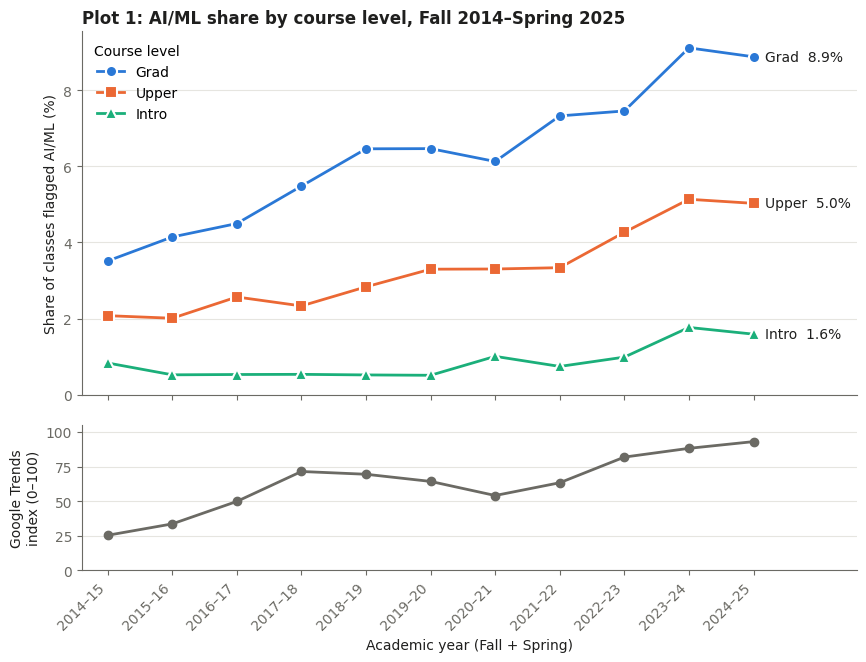

Correlation between years_since_start and trends_lag1: r = 0.86

AI/ML share (%) by level and academic year:


academic_year,2014–15,2015–16,2016–17,2017–18,2018–19,2019–20,2020–21,2021–22,2022–23,2023–24,2024–25
course_level,,,,,,,,,,,
Intro,0.8,0.5,0.5,0.5,0.5,0.5,1.0,0.7,1.0,1.8,1.6
Upper,2.1,2.0,2.6,2.3,2.8,3.3,3.3,3.3,4.3,5.1,5.0
Grad,3.5,4.1,4.5,5.5,6.5,6.5,6.1,7.3,7.5,9.1,8.9


In [11]:
# Plot 1: AI/ML share by course level per academic year, with Google Trends in its own panel below
LEVEL_STYLE = {"Grad": ("#2a78d6", "o"), "Upper": ("#eb6834", "s"), "Intro": ("#1baf7a", "^")}
INK, MUTED, GRID = "#1f1f1e", "#6b6a64", "#e6e5e0"

level_by_ay = (courses_unique.groupby(["academic_year", "course_level"])["is_ai"].mean()
               .unstack() * 100)
trends_by_ay = courses_unique.groupby("academic_year")["trends_index"].mean()
x = np.arange(len(level_by_ay))

fig, (ax, ax_t) = plt.subplots(2, 1, figsize=(10, 7), sharex=True,
                               gridspec_kw={"height_ratios": [3, 1.2], "hspace": 0.12})
for level, (color, marker) in LEVEL_STYLE.items():
    y = level_by_ay[level].values
    ax.plot(x, y, color=color, linewidth=2, marker=marker, markersize=8,
            markeredgecolor="white", markeredgewidth=1.5, label=level)
    ax.annotate(f"{level}  {y[-1]:.1f}%", (x[-1], y[-1]), xytext=(8, 0),
                textcoords="offset points", va="center", color=INK, fontsize=10)

ax.set_ylabel("Share of classes flagged AI/ML (%)", color=INK)
ax.set_title("Plot 1: AI/ML share by course level, Fall 2014–Spring 2025", loc="left",
             fontweight="bold", color=INK)
ax.legend(title="Course level", frameon=False, loc="upper left")
ax.set_ylim(0, None)

ax_t.plot(x, trends_by_ay.values, color=MUTED, linewidth=2, marker="o", markersize=6)
ax_t.set_ylabel("Google Trends\nindex (0–100)", color=INK)
ax_t.set_ylim(0, 105)
ax_t.set_xticks(x)
ax_t.set_xticklabels(level_by_ay.index, rotation=45, ha="right")
ax_t.set_xlabel("Academic year (Fall + Spring)", color=INK)

for a in (ax, ax_t):
    a.grid(axis="y", color=GRID)
    a.spines[["top", "right"]].set_visible(False)
    a.spines[["left", "bottom"]].set_color(MUTED)
    a.tick_params(colors=MUTED)
ax.set_xlim(-0.4, len(x) + 0.6)
plt.show()

r = dept_sem[["years_since_start", "trends_lag1"]].corr().iloc[0, 1]
print(f"Correlation between years_since_start and trends_lag1: r = {r:.2f}\n")
print("AI/ML share (%) by level and academic year:")
level_by_ay[["Intro", "Upper", "Grad"]].round(1).T

**Plot 1 takeaways:**

* **Every level grew, and graduate courses lead throughout.** From 2014–15 to 2024–25:
  * Grad: 3.5% → 8.9%
  * Upper: 2.1% → 5.0%
  * Intro: 0.8% → 1.6%

  Graduate courses had the highest share every single year, which fits the idea that AI/ML enters through graduate courses first.
* **No clear trickle-down yet.** The intro share doubled, but the graduate share grew about 2.5 times. The gap between them *widened*, from 2.7 to 7.3 percentage points. Intro stayed flat at about 0.5% from 2015–16 to 2019–20 and only started rising after 2020–21, with its biggest jump in 2023–24. If trickle-down is happening, it is recent. That is exactly what the `years × is_intro` interaction in Analysis 1 will test, and it is why adding the Fall 2025+ semesters matters.
* **Intro numbers are small.** Only 27 intro AI/ML class-semesters appear in the second half of our window, so a year-to-year wiggle in the green line is just a few courses. The regression uses every semester rather than reading single points.
* **Public interest and course shares rise together.** The Trends panel climbs alongside all three lines, and time and lagged Trends are correlated at r = 0.86. That makes the two hard to separate in a regression (see Questions for Reviewers).

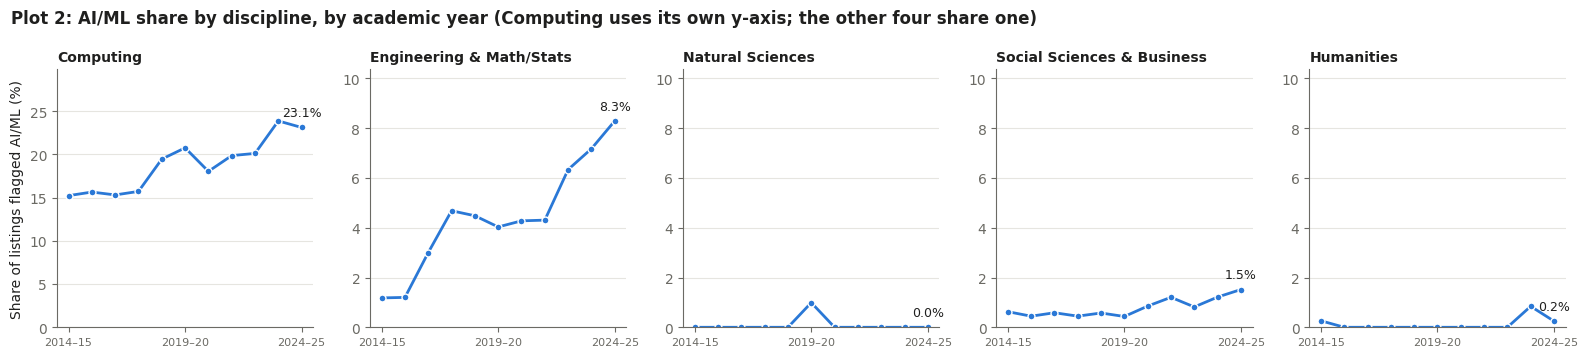

AI/ML share (%) by discipline and academic year:


academic_year,2014–15,2015–16,2016–17,2017–18,2018–19,2019–20,2020–21,2021–22,2022–23,2023–24,2024–25
discipline,,,,,,,,,,,
Computing,15.2,15.7,15.3,15.7,19.5,20.8,18.0,19.9,20.1,23.9,23.1
Engineering & Math/Stats,1.2,1.2,3.0,4.7,4.5,4.0,4.3,4.3,6.3,7.2,8.3
Natural Sciences,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
Social Sciences & Business,0.6,0.4,0.6,0.4,0.6,0.4,0.9,1.2,0.8,1.2,1.5
Humanities,0.3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.8,0.2


In [12]:
# Plot 2: AI/ML share by discipline over time, one small panel per discipline.
# Computing gets its own y-axis (it is ~20x larger); the other four share one scale so they compare fairly.
disc_by_ay = (courses.groupby(["academic_year", "discipline"])["is_ai"].mean().unstack() * 100)[disc_order]
x = np.arange(len(disc_by_ay))
ticks = [0, 5, 10]
shared_max = disc_by_ay.drop(columns="Computing").values.max() * 1.25

fig, axes = plt.subplots(1, 5, figsize=(16, 3.6), sharex=True)
for a, disc in zip(axes, disc_order):
    y = disc_by_ay[disc].values
    a.plot(x, y, color="#2a78d6", linewidth=2, marker="o", markersize=5,
           markeredgecolor="white", markeredgewidth=1)
    a.set_title(disc, loc="left", fontsize=10, color=INK, fontweight="bold")
    a.annotate(f"{y[-1]:.1f}%", (x[-1], y[-1]), xytext=(0, 8), textcoords="offset points",
               ha="center", fontsize=9, color=INK)
    a.set_ylim(0, y.max() * 1.25 if disc == "Computing" else shared_max)
    a.set_xticks([x[i] for i in ticks])
    a.set_xticklabels([disc_by_ay.index[i] for i in ticks], fontsize=8)
    a.grid(axis="y", color=GRID)
    a.spines[["top", "right"]].set_visible(False)
    a.spines[["left", "bottom"]].set_color(MUTED)
    a.tick_params(colors=MUTED)
axes[0].set_ylabel("Share of listings flagged AI/ML (%)", color=INK)
fig.suptitle("Plot 2: AI/ML share by discipline, by academic year (Computing uses its own y-axis; the other four share one)",
             x=0.01, ha="left", fontweight="bold", color=INK)
plt.tight_layout()
plt.show()

print("AI/ML share (%) by discipline and academic year:")
disc_by_ay.round(1).T

**Plot 2 takeaways:**

* **Computing grew from about 15% to 23% AI/ML** and is still far ahead of every other area.
* **Engineering & Math/Stats grew the most in relative terms, from 1.2% to 8.3%.** This is driven by ORIE, ECE, and STSCI. It is the strongest sign of spread, but into fields right next to computing. That is why Analysis 2 includes the `is_computing_broad` robustness check.
* **Social Sciences & Business went from 0.6% to 1.5%,** mostly after 2020–21. This comes from courses like ECON's machine-learning econometrics and HD/PSYCH's data science courses. But 25 of this group's 63 AI/ML listings are cross-listed, so part of the growth is shared courses, not new ones. That is why we preregistered the cross-listing robustness check.
* **Natural Sciences and Humanities are essentially zero** (1 and 5 AI/ML listings in 11 years). Some of those are the neuroscience and ethics false positives from our audit.
* **Takeaway for Analysis 2:** so far, "spread beyond computing" mostly means spread into quantitative neighbors, with a small recent rise in the social sciences.

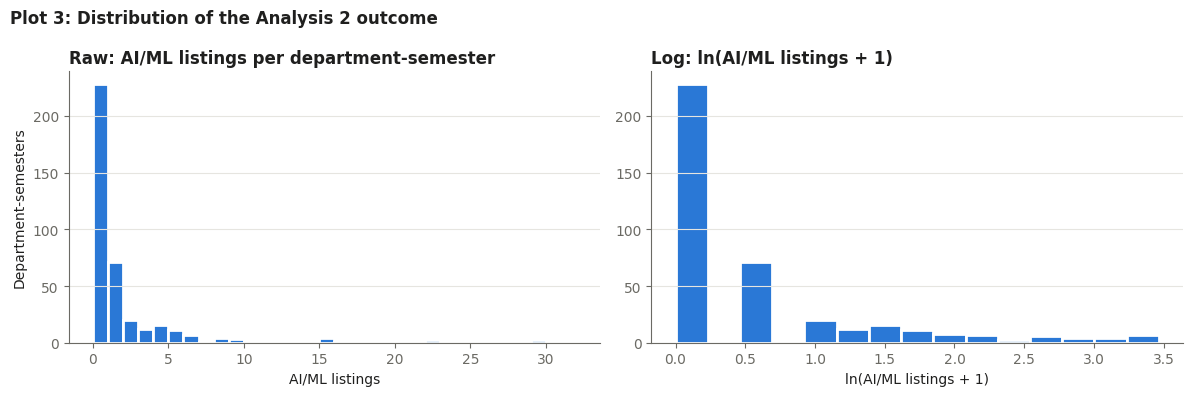

Share of department-semesters with zero AI/ML listings: 57.6%
Skewness raw: 3.65 | after log: 1.52
Mean AI/ML listings per semester, by department:


subject,CS,INFO,ORIE,ECE,STSCI,ECON,MATH,PSYCH,SOC,HD,PHIL,GOVT,AEM,PHYS,BIOG,HIST,COMM,ENGL
mean,20.41,5.59,3.32,3.18,1.55,1.09,0.73,0.55,0.5,0.32,0.23,0.23,0.18,0.05,0.0,0.0,0.0,0.0


In [13]:
# Plot 3: Is the department-semester AI count skewed enough to need a log?
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
a1.hist(dept_sem["ai_courses"], bins=range(0, dept_sem["ai_courses"].max() + 2),
        color="#2a78d6", edgecolor="white", linewidth=2)
a1.set_title("Raw: AI/ML listings per department-semester", loc="left", fontweight="bold", color=INK)
a1.set_xlabel("AI/ML listings", color=INK)
a1.set_ylabel("Department-semesters", color=INK)

a2.hist(dept_sem["log_ai_courses"], bins=15, color="#2a78d6", edgecolor="white", linewidth=2)
a2.set_title("Log: ln(AI/ML listings + 1)", loc="left", fontweight="bold", color=INK)
a2.set_xlabel("ln(AI/ML listings + 1)", color=INK)

for a in (a1, a2):
    a.grid(axis="y", color=GRID)
    a.spines[["top", "right"]].set_visible(False)
    a.spines[["left", "bottom"]].set_color(MUTED)
    a.tick_params(colors=MUTED)
fig.suptitle("Plot 3: Distribution of the Analysis 2 outcome", x=0.01, ha="left",
             fontweight="bold", color=INK)
plt.tight_layout()
plt.show()

print(f"Share of department-semesters with zero AI/ML listings: {(dept_sem['ai_courses'] == 0).mean():.1%}")
print(f"Skewness raw: {dept_sem['ai_courses'].skew():.2f} | after log: {dept_sem['log_ai_courses'].skew():.2f}")
print("Mean AI/ML listings per semester, by department:")
dept_sem.groupby("subject")["ai_courses"].mean().sort_values(ascending=False).round(2).to_frame("mean").T

**Plot 3 takeaways:**

* **The outcome is extremely right-skewed.** 57.6% of department-semesters have zero AI/ML listings, while CS averages about 20 per semester. Raw skewness is 3.65.
* **The log helps but doesn't fix the zeros.** Taking ln(count + 1) cuts skewness to 1.52 and pulls CS's very high counts in, so one department doesn't dominate the regression line. It can't do anything about the large spike at zero, though.
* **What we'll do about it:** we keep the preregistered log-OLS model from lecture as our main analysis, and add a Poisson regression on the raw counts as a robustness check, since Poisson is designed for counts with many zeros.

### **Preregistered Analysis 1: Does AI/ML "trickle down" from graduate to introductory courses?**

* **Hypothesis.** New technical fields usually enter a university through graduate seminars, and faculty build introductory material later. We expect graduate courses to start with the highest AI/ML share, but the introductory share to grow **faster per year** than the graduate share, so the levels move closer together over time.

* **Data and unit of observation.** `courses_unique`: one row per class per semester, with cross-listings counted once and placeholder courses removed (N = 18,774 class-semesters, 747 flagged AI/ML).

* **Outcome.** `is_ai` (1 if the class's title or description contains an AI/ML keyword, 0 otherwise).

* **Predictors, and why each is included.**
  * `years_since_start` (0 = Fall 2014, in years): the overall time trend for graduate courses, our comparison group.
  * `is_intro`, `is_upper`: how far below or above `Grad` each level starts in Fall 2014.
  * `years_since_start × is_intro`, `years_since_start × is_upper`: how much faster or slower each level's AI/ML share grows than `Grad`. **These interaction terms are the actual test of trickle-down.**
  * `trends_lag1`: the previous semester's public interest in AI. It is included as a control so that a general rise in AI attention isn't mistaken for level-specific growth.

* **Method.** `is_ai` is 0 or 1, and a straight-line regression could predict probabilities below 0 or above 1. So we fit a **logistic regression**:

  $$\log\frac{P(\text{is\_ai}=1)}{1-P(\text{is\_ai}=1)} = \beta_0 + \beta_1\,\text{years} + \beta_2\,\text{is\_intro} + \beta_3\,\text{is\_upper} + \beta_4\,\text{trends\_lag1} + \beta_5\,(\text{years}\times\text{is\_intro}) + \beta_6\,(\text{years}\times\text{is\_upper})$$

  We report each coefficient as an **odds ratio**, $e^{\beta}$. The same course is offered in many semesters, so its rows aren't independent. We therefore cluster standard errors by `crse_id` to avoid overstating our certainty.

* **What would support the hypothesis.** $\beta_2 < 0$ (intro courses start lower) **and** $\beta_5 > 0$ with $p < 0.05$ (intro courses grow faster than graduate courses). If $\beta_5$ is zero or negative, AI/ML is not trickling down within our window. We will report the full regression table either way.

### **Preregistered Analysis 2: Is AI/ML spreading from computing departments into other fields?**

* **Hypothesis.** As AI tools become usable without a CS background, departments outside computing add AI/ML to their own catalogs. We expect CS and INFO to offer far more AI/ML courses, but non-computing departments to show **positive yearly growth** in AI/ML offerings, even after accounting for department size and public interest.

* **Data and unit of observation.** `dept_sem`: one row per department per semester (18 departments × 22 semesters = 396 rows). Cross-listings count toward every department that lists them; see Step 5 for why.

* **Outcome.** `log_ai_courses` = ln(AI/ML listings + 1). Plot 3 shows the raw counts are strongly right-skewed, and the log makes slopes readable as percentage changes.

* **Predictors, and why each is included.**
  * `years_since_start`: the yearly growth rate for non-computing departments (our comparison group). **This is the main test of spread.**
  * `is_computing`: how much higher CS and INFO start.
  * `years_since_start × is_computing`: whether computing departments are growing faster (pulling further ahead) or slower (others catching up).
  * `trends_lag1`: the previous semester's public interest in AI.
  * `total_courses`: department size that semester. A department with 200 courses will have more AI/ML courses by chance than one with 30, and we don't want to confuse size with AI focus.

* **Method.** **Ordinary least squares (OLS)** regression on the log outcome:

  $$\ln(\text{ai\_courses}+1) = \alpha_0 + \alpha_1\,\text{years} + \alpha_2\,\text{trends\_lag1} + \alpha_3\,\text{is\_computing} + \alpha_4\,\text{total\_courses} + \alpha_5\,(\text{years}\times\text{is\_computing}) + \varepsilon$$

  We convert slopes into percentages with $100\times(e^{\alpha}-1)\%$. For example, $\alpha_1$ becomes the yearly percentage change in AI/ML offerings for a non-computing department. Each department appears 22 times, so we cluster standard errors by department.

  We will also check our assumptions:
  * a residuals-vs-fitted plot, for uneven spread (heteroskedasticity);
  * Variance Inflation Factors (VIF), because `years_since_start` and `trends_lag1` both rise over time and may overlap.

* **Robustness checks (decided now, before seeing results).**
  1. **Engineering counted as computing.** Our audit found that much of the AI/ML outside CS and INFO is in ORIE, ECE, and STSCI. We will re-run the model with `is_computing_broad` (which also counts Engineering & Math/Stats as computing) to see whether "spread beyond computing" holds when engineering doesn't count as "beyond."
  2. **Cross-listings removed.** We will re-run with cross-listed AI/ML courses removed from each department's count, to see whether growth comes from departments creating their own courses or from cross-listing CS courses.
  3. **Count model.** Plot 3 shows 58% of department-semesters have zero AI/ML courses, which the log can't fix. We will also fit a Poisson regression on the raw count `ai_courses` (with `total_courses` as the size control), which is designed for count data with many zeros, and check that it gives the same direction of results.

* **What would support the hypothesis.** $\alpha_1 > 0$ with $p < 0.05$ in the main model, and still positive in all three robustness checks.

### **Questions for Reviewers**

1. **Separating time from public interest.** `years_since_start` and `trends_lag1` are strongly correlated in our data (r = 0.86, printed under Plot 1), so the regressions may struggle to tell their effects apart. If our VIF check confirms this, would it be better to use the *semester-to-semester change* in Trends, or to drop Trends from the main models and test it separately?

2. **Checking our AI/ML flag.** In Phase I, our TA suggested comparing ways of identifying AI courses. For Phase III, we plan to hand-label a random sample of about 100 courses (stratified so that flagged and non-flagged courses are both included), compare our labels to `is_ai`, and report false-positive and false-negative rates. Is that sample size and approach enough?

3. **Adding instructors.** Our TA suggested looking at who teaches each course and whether their research is in AI/ML. The roster API includes instructor NetIDs for each class section, which we did not collect yet. We could match instructors to research topics using OpenAlex or department pages, to test whether AI/ML courses outside computing are taught by AI researchers or by faculty from other fields adopting AI. Is this worth adding in Phase III, given name-matching errors and missing instructors for some sections?

4. **Coverage.** We sampled 18 subjects across five broad disciplines rather than all of Cornell. Is this sample enough for the discipline comparison, or should we prioritize scraping more subjects (or the Fall 2025–Fall 2026 catalog) before Phase III?